# 01 — Source Extraction and Data Audit

## Research objective
Establish what the two original datasets actually contain before choosing training examples.
This notebook preserves source files, records checksums, checks annotation geometry and
produces visual evidence. **Missing labels are never interpreted as healthy cases.**

| Source | Task | Original archive |
|---|---|---|
| Zenodo 14827784 | Visible dental caries | `data/raw/caries/Dataset.zip` |
| Mendeley 3253gj88rr, version 1 | Gingival appearance | `data/raw/gum/Dataset.rar` |

## Workflow
1. Extract and verify original archives.
2. Inventory images and annotation files.
3. Inspect annotation formats, image geometry and label semantics.
4. Report exclusions, duplicates and source limitations.

This is data preparation, not a clinical validation study or a training run.

## 1. Reproducible local environment

Use the project Python 3.11 environment with the `research` dependency extra. No GPU is required.

In [1]:
from pathlib import Path
import json
import sys
import platform
import pandas as pd
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "src/configs/sources.json").is_file())
REPORT = ROOT / "docs/reports/data_preparation"
REPORT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 85)
print("Python:", platform.python_version())
print("Project:", ROOT)


Python: 3.11.15
Project: C:\Users\huynh\Desktop\oral-disease


## 2. Extract and verify both sources

Caries uses a publisher MD5. Gingivitis receives a local SHA-256 fingerprint; this is not misrepresented as publisher verification. Extraction is skipped only when every expected member already exists at the expected size.

In [2]:
from dentalselfie.research import extract_sources, source_inventory

extraction = extract_sources(ROOT)
extraction.to_csv(REPORT / "archive_verification.csv", index=False)
display(extraction)


,task,archive,archive_bytes,extracted_files,checksum,status
0,caries,data\raw\caries\Dataset.zip,1576115314,13003,Publisher MD5 matched,extracted and verified
1,gum,data\raw\gum\Dataset.rar,6552111937,2195,Local SHA-256 recorded,extracted and verified


## 3. Inventory the extracted files

Counts are measured from disk, rather than copied from dataset descriptions. Original captions are retained for provenance, but will not be model inputs.

In [3]:
inventory = source_inventory(ROOT)
inventory.to_csv(REPORT / "source_inventory.csv", index=False)
display(inventory.groupby(["task", "extension"]).agg(files=("path", "size"), bytes=("bytes", "sum")))


files       bytes
task   extension                   
caries .jpg        6265  1105361461
       .json       2248   638246358
       .txt        2245      548209
       .xml        2245     1697245
gum    .csv           3      825729
       .jpg        1096  6554940692
       .txt        1096      584777

## 4. Annotation schema inspection

Inspect real source rows before the full checks below. No source mapping is approved from a paper alone.

In [4]:
for task in ("caries", "gum"):
    source = ROOT / "data/raw" / task / "Dataset"
    label_files = sorted(source.rglob("*.txt"))
    print(f"{task}: {len(label_files):,} text annotation files")
    for path in label_files[:2]:
        print(path.relative_to(ROOT).as_posix())
        print(path.read_text(encoding="utf-8-sig")[:900])


caries: 2,245 text annotation files
data/raw/caries/Dataset/Annotations/Darknet_YOLO/no_retractors/Frontal/anonymous_003-007-1214-00_1732862917124_Frontal_View.txt
0 0.2012863952219607 1.7460885571121791 0.28570608166312533 0.2991103384804173

data/raw/caries/Dataset/Annotations/Darknet_YOLO/no_retractors/Frontal/anonymous_003-007-673-00_1729239709286_Frontal_View.txt
1 0.9332763857251328 0.597972972972973 0.05789673500379651 0.24662162162162163

gum: 1,096 text annotation files
data/raw/gum/Dataset/Test/Labels/00929.txt
2 0.291440 0.386401 0.074185 0.122150
2 0.364130 0.428746 0.073098 0.100163
3 0.463927 0.431087 0.118071 0.117467
2 0.574660 0.443607 0.105571 0.107899
2 0.670380 0.436482 0.081522 0.112785
2 0.741916 0.425590 0.072147 0.109731
3 0.323302 0.774837 0.079484 0.131515
3 0.405774 0.796824 0.079484 0.131515
3 0.483220 0.798453 0.079484 0.131515
3 0.560530 0.808021 0.079484 0.131515
3 0.643003 0.806393 0.079484 0.131515
3 0.720313 0.801710 0.079484 0.131515
0 0.517188 0.4733

## 5. Image readability and reproducible fingerprints

Every extracted image is checked. File SHA-256 detects byte-identical files;
64-bit pHash and dHash identify conservative visual similarity candidates.
JPEG draft decoding accelerates preview analysis without changing source pixels or labels.
The cache is reused only when the source path, file size and modification timestamp match.

In [5]:
from dentalselfie.research import inspect_images, audit_annotations, caries_format_summary

images = inspect_images(ROOT, inventory, REPORT / "image_inventory.csv", workers=4)
display(images.groupby("task").agg(images=("image_path", "size"),
                                    min_width=("width", "min"), max_width=("width", "max"),
                                    min_height=("height", "min"), max_height=("height", "max")))
display(images.loc[images.decode_error != "", ["task", "image_path", "decode_error"]])


,images,min_width,max_width,min_height,max_height
task,,,,,
caries,6265,617,4080,347,3206
gum,1096,6969,7286,4641,4863


,task,image_path,decode_error


## 6. Resolve source formats before combining labels

**Caries:** the canonical source is the named rectangle annotation in LabelMe.
`D` and `d` both map to `visible_caries`. COCO category IDs must be interpreted
inside each JSON file; a numeric ID is not a universal disease label.

**Gingiva:** source classes 0 and 1 are anatomical jaw ROIs. Classes 2–6 correspond
to MGI 0–4 according to [Table 2 and the labeling section of the source paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC11462013/).
We cross-check those semantics with actual caption/label examples and visual geometry.
Captions are audit evidence only, never model features.

In [6]:
format_coverage, coco_categories = caries_format_summary(ROOT)
display(format_coverage)
display(coco_categories)
coco_categories.to_csv(REPORT / "caries_coco_categories.csv", index=False)

records, annotations = audit_annotations(ROOT, images)
annotations.to_csv(REPORT / "source_annotations.csv", index=False)
display(annotations.groupby(["task", "source_class"]).agg(
    boxes=("box_index", "size"), valid_boxes=("valid_geometry", "sum")))


,format,files
0,Darknet_YOLO,2245
1,Labelme,2245
2,pascal-voc,2245


,file,category_id,name,images_in_file,boxes_in_file
0,test.json,1,D,232,690
1,test.json,2,d,232,690
2,train.json,1,d,1781,5386
3,train.json,2,D,1781,5386
4,valid.json,1,d,214,652
5,valid.json,2,D,214,652


boxes  valid_boxes
task   source_class                    
caries D              6174         6134
       d               552          552
gum    0              1096         1096
       1              1096         1096
       2               309          309
       3              1831         1831
       4              3851         3851
       5              4867         4866
       6              2292         2292

## 7. Verify gingivitis semantics against independent source descriptions

The three expected histograms below were transcribed from the original captions for
these image IDs. Jaw ROI labels are omitted from the histogram. A mismatch would stop
this semantic check rather than silently shifting class indices.
Published table counts are not substituted for measured archive counts.

In [7]:
from collections import Counter

expected_examples = {
    "00929": {2: 5, 3: 7},
    "00001": {3: 4, 4: 4, 5: 4},
    "00733": {5: 6, 6: 6},
}
checks = []
gum_records = records[records.task == "gum"]
for image_id, expected in expected_examples.items():
    matches = gum_records[gum_records.image_path.map(lambda value: Path(value).stem == image_id)]
    assert len(matches) == 1
    observed = dict(sorted(Counter(int(box["source_class"]) for box in matches.iloc[0].source_boxes
                                   if int(box["source_class"]) >= 2).items()))
    checks.append({"image_id": image_id, "caption_expected": json.dumps(expected),
                   "annotation_observed": json.dumps(observed), "matches": observed == expected})
caption_checks = pd.DataFrame(checks)
display(caption_checks)
assert caption_checks.matches.all(), "Investigate the source class interpretation before preparing data"
caption_checks.to_csv(REPORT / "gingivitis_caption_checks.csv", index=False)

measured_gum = annotations[annotations.task == "gum"].groupby(
    ["source_class", "source_split"]).size().unstack(fill_value=0)
display(measured_gum)
measured_gum.to_csv(REPORT / "gingivitis_measured_class_counts.csv")


,image_id,caption_expected,annotation_observed,matches
0,00929,"{""2"": 5, ""3"": 7}","{""2"": 5, ""3"": 7}",True
1,00001,"{""3"": 4, ""4"": 4, ""5"": 4}","{""3"": 4, ""4"": 4, ""5"": 4}",True
2,00733,"{""5"": 6, ""6"": 6}","{""5"": 6, ""6"": 6}",True


source_split,Test,Training,Validation
source_class,,,
0,182,732,182
1,182,732,182
2,35,244,30
3,307,1218,306
4,899,2178,774
5,713,3399,755
6,221,1751,320


## 8. Inspect box geometry visually

We render deterministic source examples across the file list. For gingivitis,
the ordinary YOLO width/height interpretation is compared with a swapped-column
hypothesis because the paper's prose is inconsistent. The selected interpretation
must align with the actual anatomy. These overlays verify annotation geometry,
not the clinical correctness of the original diagnoses.

If any disease box is invalid, its entire image is quarantined. We never repair
out-of-frame boxes by clipping or silently remove one lesion while keeping its image.

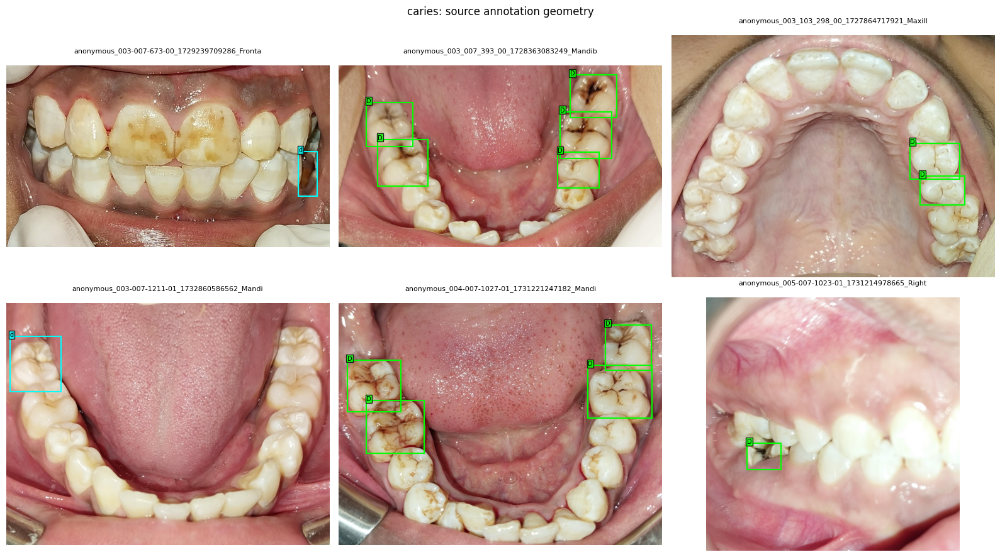

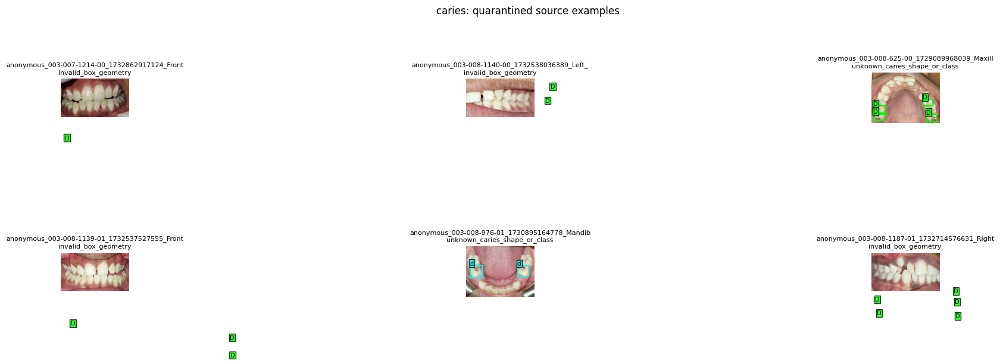

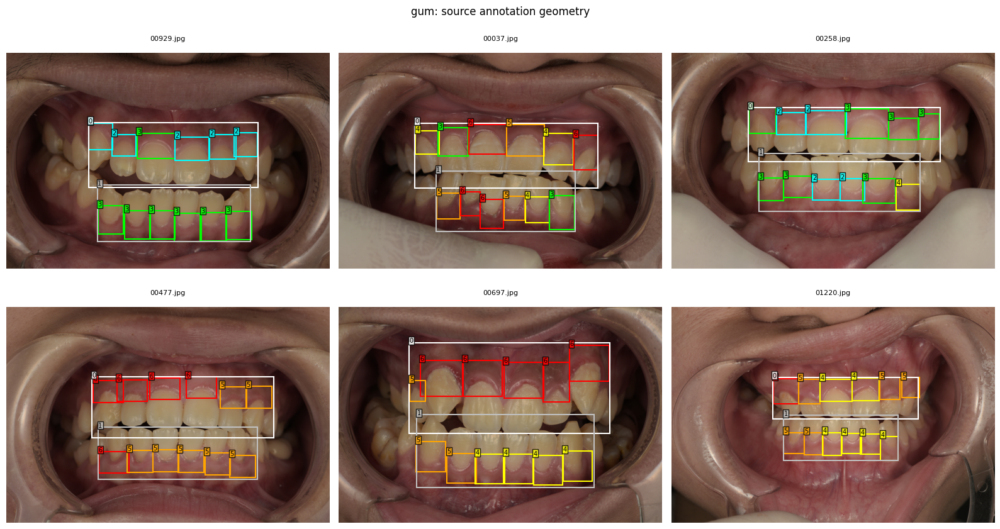

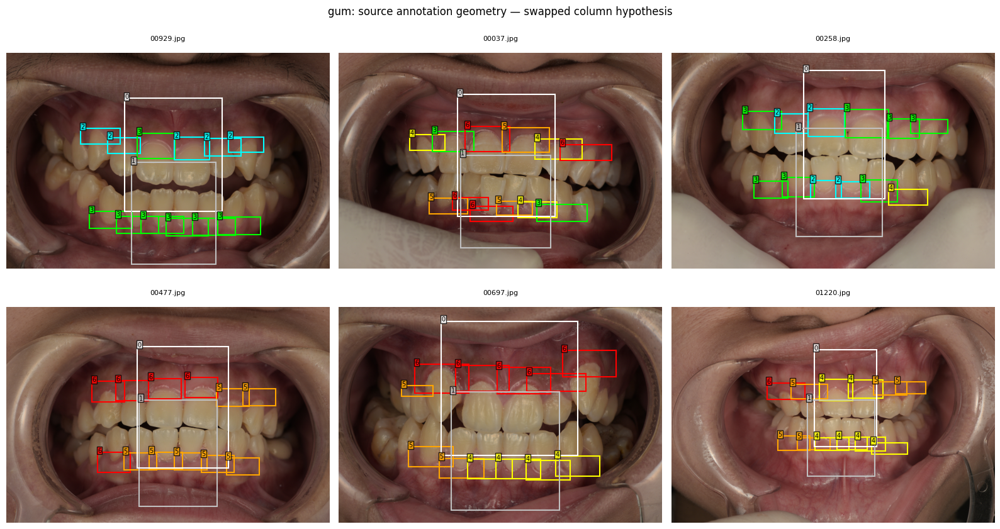

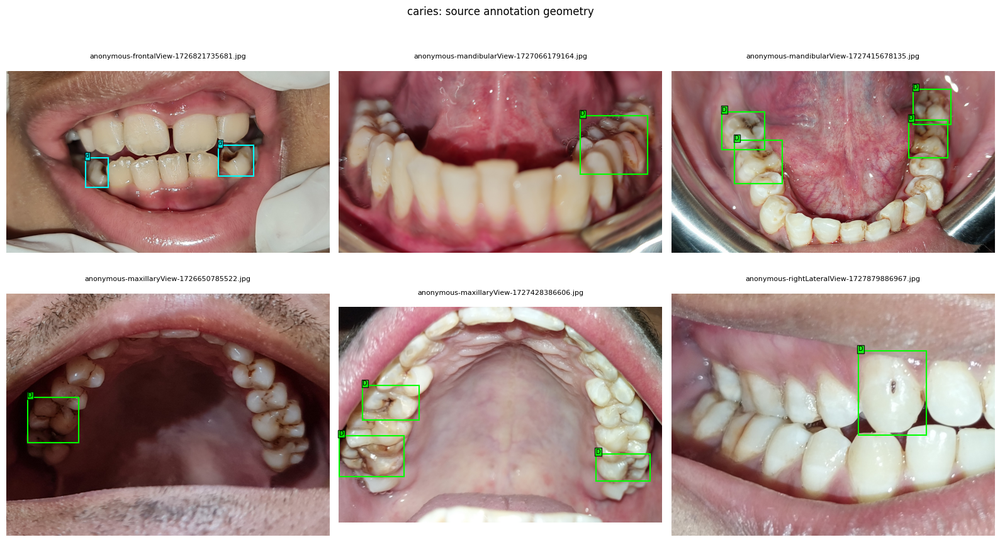

In [8]:
import matplotlib.pyplot as plt
from dentalselfie.research import plot_annotation_grid

plot_annotation_grid(ROOT, records, REPORT / "caries_valid_overlays.png", "caries")
plt.show()
plot_annotation_grid(ROOT, records, REPORT / "caries_quarantine_overlays.png", "caries", invalid=True)
plt.show()
plot_annotation_grid(ROOT, records, REPORT / "gingivitis_standard_overlays.png", "gum")
plt.show()
plot_annotation_grid(ROOT, records, REPORT / "gingivitis_swapped_overlays.png", "gum", swap_gum_dimensions=True)
plt.show()
orientation_zero = records[(records.task == "caries") & (records.exif_orientation == 0) & records.eligible]
plot_annotation_grid(ROOT, orientation_zero, REPORT / "caries_orientation0_review.png", "caries")
plt.show()


### Recorded interpretation after visual review

The standard gingivitis width/height interpretation aligns with the source regions;
the swapped hypothesis visibly misplaces the jaw and gingival boxes. The source
class semantics match the three independent caption examples above.

Caries LabelMe boxes align with stored image pixels. Orientation tag 0 does not
define a rotation: these images are kept in stored-pixel orientation after dimension
checks and the dedicated overlay review above. Defined rotations other than identity
remain quarantined. Prepared JPEGs contain no EXIF orientation metadata. Unknown
source labels `M`/`m` and non-rectangle shapes are quarantined, not guessed.

## 9. Audit exclusions and missing annotations

Unannotated caries images remain available in the immutable source directory but
are excluded from supervised training. Explicitly empty, valid annotation files
may represent negative examples. No missing file is converted into an empty label.

In [9]:
reason_counts = (records[["task", "reasons"]].explode("reasons")
                 .dropna().groupby(["task", "reasons"]).size().rename("images").reset_index())
display(reason_counts)
reason_counts.to_csv(REPORT / "annotation_issue_counts.csv", index=False)
display(records.groupby("task").agg(source_images=("sample_id", "size"),
                                     geometry_eligible=("eligible", "sum")))


,task,reasons,images
0,caries,invalid_box_geometry,14
1,caries,missing_annotation_not_a_negative,4038
2,caries,nonstandard_exif_orientation_requires_review,5
3,caries,unknown_caries_shape_or_class,38
4,gum,invalid_box_geometry,1


,source_images,geometry_eligible
task,,
caries,6265,2175
gum,1096,1095


## 10. Duplicate candidates and same-split constraints

Before splitting, we join shared filename case tokens, byte-identical images and
visual candidates with pHash distance ≤ 4 **and** dHash distance ≤ 4, with similar
aspect ratios. Similarity creates a conservative same-split constraint, not a claim
that two images show the same patient. Filename-derived case tokens are also not
independently verified patient IDs. Exact duplicate examples are deduplicated;
conflicting duplicate annotations are quarantined.

The resulting holdout is group-isolated under these observable constraints.
It cannot certify that every unknown repeated patient has been detected.

In [10]:
from dentalselfie.research import duplicate_pairs, assign_groups

pairs = duplicate_pairs(records, radius=4)
pairs.to_csv(REPORT / "duplicate_candidates.csv", index=False)
display(pairs.groupby(["task", "relation"]).size().rename("pairs").reset_index()
        if len(pairs) else pd.DataFrame(columns=["task", "relation", "pairs"]))
records = assign_groups(records, pairs)
display(records.groupby("task").agg(source_images=("sample_id", "size"),
                                     retained_candidates=("eligible", "sum"),
                                     constraint_groups=("group_id", "nunique")))


,task,relation,pairs
0,caries,visual_candidate,65
1,gum,exact_bytes,14
2,gum,visual_candidate,2


,source_images,retained_candidates,constraint_groups
task,,,
caries,6265,2175,1817
gum,1096,1067,1081


## 11. Inspect representative visual pairs

These examples make the duplicate rule reviewable. All detected pairs remain in the CSV, including those not shown here.

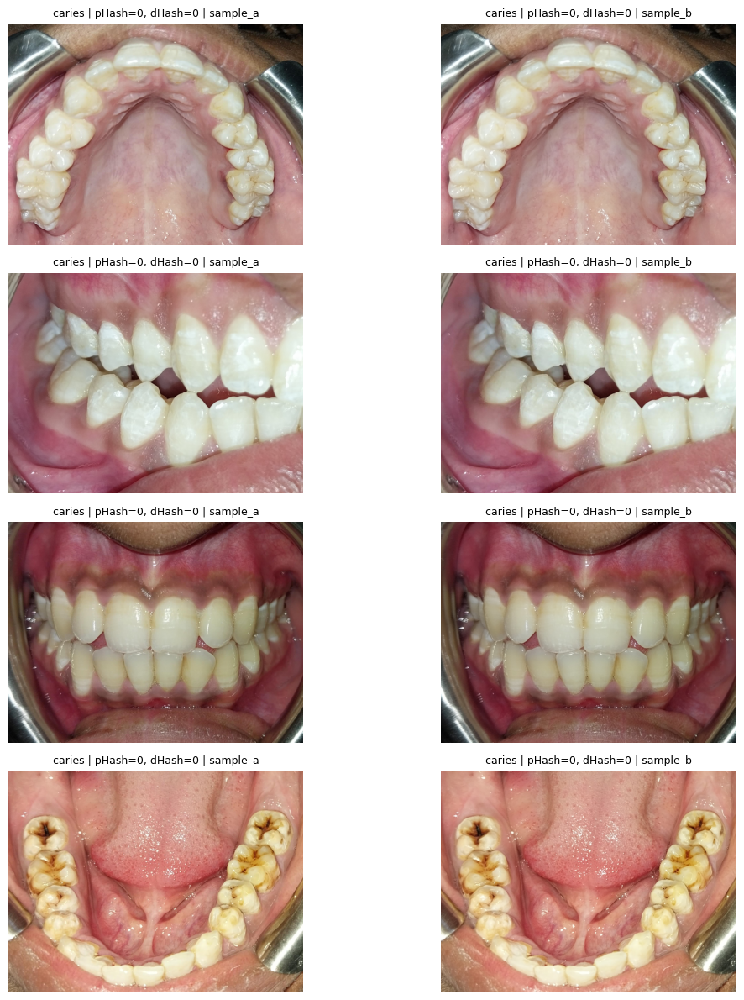

In [11]:
from PIL import Image

examples = pairs.sort_values(["phash_distance", "dhash_distance", "sample_a"]).head(4)
lookup = records.set_index("sample_id")
if len(examples):
    fig, axes = plt.subplots(len(examples), 2, figsize=(12, 3 * len(examples)), squeeze=False)
    for row_index, pair in enumerate(examples.to_dict("records")):
        for column_index, key in enumerate(("sample_a", "sample_b")):
            image_row = lookup.loc[pair[key]]
            with Image.open(ROOT / image_row.image_path) as image:
                image.draft("RGB", (700, 700))
                axes[row_index, column_index].imshow(image.convert("RGB"))
            axes[row_index, column_index].axis("off")
            axes[row_index, column_index].set_title(
                f"{pair['task']} | pHash={pair['phash_distance']}, dHash={pair['dhash_distance']} | {key}", fontsize=9)
    fig.tight_layout()
    fig.savefig(REPORT / "duplicate_pair_examples.png", dpi=140)
    plt.show()


## 12. Export the audit handoff

Notebook 02 consumes the complete per-image audit, not only the displayed samples. Raw files remain unchanged.

In [12]:
from dentalselfie.research import write_json
from IPython.display import Markdown

records.to_json(REPORT / "audit_records.jsonl", orient="records", lines=True, double_precision=15)
quarantine = records[~records.eligible][["task", "sample_id", "image_path", "label_path", "reasons"]].copy()
quarantine["reasons"] = quarantine.reasons.map(lambda items: "; ".join(items))
quarantine.to_csv(REPORT / "quarantine.csv", index=False)
summary = records.groupby("task").agg(source_images=("sample_id", "size"),
                                       retained_candidates=("eligible", "sum")).reset_index()
summary["excluded_images"] = summary.source_images - summary.retained_candidates
summary.to_csv(REPORT / "audit_summary.csv", index=False)
display(summary)
final_reasons = (records[["task", "reasons"]].explode("reasons").dropna()
                 .groupby(["task", "reasons"]).size().rename("images").reset_index())
final_reasons.to_csv(REPORT / "final_exclusion_reasons.csv", index=False)
display(final_reasons)
write_json(REPORT / "audit_protocol.json", {
    "version": "1", "caries_source": "LabelMe named rectangles", "gum_columns": "class cx cy width height",
    "near_duplicate_rule": "pHash<=4 AND dHash<=4 AND aspect ratio within 10%",
    "quarantine_policy": "Any invalid annotation excludes the whole image; missing is not negative",
    "independence_limit": "Observable filename/hash/visual groups; not certified patient-disjoint",
    "orientation_policy": "Stored pixels for EXIF 0/1 with dimension checks; quarantine other rotations",
})
display(Markdown(f"""### Executed conclusion

- Audited **{len(records):,} source images** from both extracted archives.
- Retained **{int(records.eligible.sum()):,} candidates** before final normalization.
- Recorded **{int((~records.eligible).sum()):,} excluded images** with explicit reasons.
- Saved **{len(pairs):,} duplicate/similarity constraints** for grouped splitting.
- No model was trained and no missing label was invented.

Next: inspect the saved geometry evidence, record the verified class mapping, then execute notebook 02."""))


,task,source_images,retained_candidates,excluded_images
0,caries,6265,2175,4090
1,gum,1096,1067,29


,task,reasons,images
0,caries,invalid_box_geometry,14
1,caries,missing_annotation_not_a_negative,4038
2,caries,nonstandard_exif_orientation_requires_review,5
3,caries,unknown_caries_shape_or_class,38
4,gum,exact_duplicate_annotation_conflict,28
5,gum,invalid_box_geometry,1


### Executed conclusion

- Audited **7,361 source images** from both extracted archives.
- Retained **3,242 candidates** before final normalization.
- Recorded **4,119 excluded images** with explicit reasons.
- Saved **81 duplicate/similarity constraints** for grouped splitting.
- No model was trained and no missing label was invented.

Next: inspect the saved geometry evidence, record the verified class mapping, then execute notebook 02.

## Implementation appendix — readable processing code

The following cell displays the exact shared implementation used above, with syntax
highlighting. Its saved output makes the processing code readable inside this notebook.
The shared module remains the single implementation so fixes do not diverge between notebooks.

In [13]:
import inspect
from IPython.display import Code
from dentalselfie import research

for function_name in ('audit_annotations', 'assign_groups'):
    print(function_name)
    display(Code(inspect.getsource(getattr(research, function_name)), language='python'))


audit_annotations


def audit_annotations(root: Path, images: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Use named LabelMe rectangles for caries and verified numeric YOLO rows for gingiva.

    Any malformed disease annotation quarantines the entire image, avoiding a
    false negative introduced by silently dropping one of its boxes.
    """
    records, annotations = [], []
    for info in images.to_dict("records"):
        path = root / info["image_path"]
        task = info["task"]
        sample_id = hashlib.sha256(info["image_path"].encode()).hexdigest()[:20]
        record = dict(info, sample_id=sample_id, label_path="", source_split="not_provided",
                      source_collection="", view="unknown", reasons=[], source_boxes=[], target_boxes=[])
        if info["decode_error"]:
            record["reasons"].append("image_decode_error")
        # Tag 0 defines no rotation. Reviewed LabelMe boxes align with stored
        # pixels, and source annotation dimensions are checked below.
        if int(info["exif_orientation"]) not in (0, 1):
            record["reasons"].append("nonstandard_exif_orientation_requires_review")
        try:
            if task == "caries":
                suffix = path.as_posix().split("/Images/", 1)[1].split("/")
                collection, view = suffix[:2]
                record.update(source_collection=collection, view=view)
                label = root / "data/raw/caries/Dataset/Annotations/Labelme" / collection / view / f"{path.stem}.json"
                match = re.search(r"anonymous_(\d{3}-\d{3}-\d+)-\d{2}_", path.stem)
                timestamp = re.search(r"\d{13}", path.stem)
                if match:
                    record.update(group_hint=f"caries:filename_case:{match.group(1)}",
                                  group_basis="Shared filename case token; patient identity is not independently verified")
                elif timestamp:
                    record.update(group_hint=f"caries:timestamp:{timestamp.group(0)}",
                                  group_basis="Shared filename timestamp only; sessions/patients may remain unlinked")
                else:
                    record.update(group_hint=f"caries:image:{sample_id}", group_basis="Image only; no reliable case token")
                if not label.is_file():
                    record["reasons"].append("missing_annotation_not_a_negative")
                else:
                    record["label_path"] = label.relative_to(root).as_posix()
                    document = json.loads(label.read_text(encoding="utf-8-sig"))
                    if (document["imageWidth"], document["imageHeight"]) != (info["width"], info["height"]):
                        record["reasons"].append("annotation_image_dimensions_mismatch")
                    if Path(document["imagePath"].replace("\\", "/")).name != path.name:
                        record["reasons"].append("annotation_image_name_mismatch")
                    for shape in document["shapes"]:
                        if shape["shape_type"] != "rectangle" or shape["label"] not in {"D", "d"}:
                            record["reasons"].append("unknown_caries_shape_or_class")
                            continue
                        (x1, y1), (x2, y2) = shape["points"]
                        record["source_boxes"].append({"source_class": shape["label"], "target_class": 0,
                                                       "xyxy": [min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2)]})
            else:
                record.update(source_split=path.parent.parent.name, source_collection="professional_frontal",
                              view="frontal", group_hint=f"gum:image_id:{path.stem}",
                              group_basis="Source image ID only; no participant identifier is supplied")
                label = path.parent.parent / "Labels" / f"{path.stem}.txt"
                if not label.is_file():
                    record["reasons"].append("missing_annotati

assign_groups


def assign_groups(records: pd.DataFrame, pairs: pd.DataFrame) -> pd.DataFrame:
    """Join filename hints, identical bytes and conservative visual candidates."""
    rows = records.to_dict("records")
    parent = {row["sample_id"]: row["sample_id"] for row in rows}

    def find(item):
        while parent[item] != item:
            parent[item] = parent[parent[item]]
            item = parent[item]
        return item

    def join(a, b):
        x, y = sorted([find(a), find(b)])
        parent[y] = x

    seen = {}
    for row in rows:
        for key in [(row["task"], "hint", row["group_hint"]), (row["task"], "sha256", row["sha256"])]:
            if key in seen:
                join(row["sample_id"], seen[key])
            else:
                seen[key] = row["sample_id"]
    for pair in pairs.to_dict("records"):
        join(pair["sample_a"], pair["sample_b"])
    for row in rows:
        row["group_id"] = f"{row['task']}:constraint:{find(row['sample_id'])}"
    # Exact duplicates do not count as extra independent examples.
    for _, subset in records[records.eligible].groupby(["task", "sha256"]):
        if len(subset) < 2:
            continue
        signatures = {json.dumps(sorted(row["target_boxes"]), sort_keys=True) for row in subset.to_dict("records")}
        ids = set(subset.sample_id) if len(signatures) != 1 else set(sorted(subset.sample_id)[1:])
        for row in rows:
            if row["sample_id"] in ids:
                reason = "exact_duplicate_annotation_conflict" if len(signatures) != 1 else "redundant_exact_duplicate"
                row["reasons"] = sorted(set(row["reasons"] + [reason]))
                row["eligible"] = False
    return pd.DataFrame(rows)